<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_4_%7C_LESSON_3_Correlation_Basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**

## MODULE 4 | LESSON 3: Correlation Basics

| | |
|:---|:---|
|**Reading Time** | 4h |
|**Prior Knowledge** | Linear algebra, matrix operations, basic statistics, hypothesis testing, portfolio theory, time series analysis, eigenvalue decomposition, Python programming |
|**Keywords** | Pearson correlation, Spearman rank correlation, Kendall's tau, Fisher transformation, correlation stationarity, rolling window analysis, DCC models, eigenvalues, eigenvectors, principal component analysis, PCA, correlation matrices, time-varying correlation, systemic risk, factor rotation, correlation breakdown, Marčenko-Pastur distribution, risk parity, correlation clustering |

---

## **Introduction**

Correlation is the financial world's most dangerous friend – indispensable when you need it, treacherous when you trust it too much.

Think about it. Every portfolio manager relies on correlation to diversify risk (why wouldn't they?). Yet precisely when diversification matters most – during market crashes – correlations have an nasty habit of converging toward one. It's like discovering your fire insurance expires during fires.

A bit more precisely, correlation measures how two variables dance together. When tech stocks rise, do biotech stocks follow? When oil prices plummet, what happens to airline shares? These co-movements shape everything from hedge fund strategies to your retirement portfolio's survival odds. But here's the thing most textbooks won't tell you: the correlation you measure today might be utterly useless tomorrow.

It pays to understand why correlation behaves so badly. First, we'll review some of the mathematical foundationsand then we'll confront the uncomfortable evidence that correlations shift, sometimes violently, making yesterday's diversification today's concentration risk. Finally, we'll explore powerful techniques that tame correlation's complexity without losing its essential information.

## **1. Linear Correlation Measures and Significance Testing**

### **1.1 The Pearson Correlation Coefficient**

For the purposes of quantitative finance, Pearson correlation is simultaneously the most used and most abused statistical measure – a bit like leverage in that respect.

The mathematical foundation looks deceptively simple. Take two variables, measure how they deviate from their means together, then normalize:

$$\rho_{X,Y} = \frac{\text{Cov}(X,Y)}{\sigma_X \sigma_Y} = \frac{E[(X-\mu_X)(Y-\mu_Y)]}{\sqrt{E[(X-\mu_X)^2]}\sqrt{E[(Y-\mu_Y)^2]}}$$

This normalization is genius, actually. Without it, you'd be comparing apples to watermelons – imagine correlating penny stock returns with S&P 500 moves in raw dollar terms. The division by standard deviations creates a scale-free measure bounded between -1 and 1. Perfect positive correlation (+1) means the variables march in lockstep; perfect negative correlation (-1) means they're perfect mirror images; zero means no linear relationship whatsoever.

Note that I said "linear" relationship (why is this crucial?). Pearson correlation is blind to non-linear patterns. Variables can be strongly related – even deterministically related – yet show zero Pearson correlation. Consider $Y = X^2$ where $X$ is symmetric around zero. Perfect dependence, zero correlation. This isn't a bug; it's a feature that becomes a bug when misunderstood.

In practice, we estimate correlation from samples:

$$r_{xy} = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^n (x_i - \bar{x})^2}\sqrt{\sum_{i=1}^n (y_i - \bar{y})^2}}$$

Financial professionals develop intuitions about correlation magnitudes. Above 0.7? That's strong – think stocks in the same sector during calm markets. Between 0.5 and 0.7 suggests moderate association, like developed market equities. Below 0.3? Weak enough to provide decent diversification. But context matters enormously (when doesn't it in finance?). A 0.5 correlation between asset classes might be alarmingly high, while 0.5 between two tech stocks seems suspiciously low.

### **1.2 Statistical Significance Testing**

Here's where many analysts stumble: computing a correlation is easy, knowing whether it means anything is hard.

The sampling distribution of correlation coefficients is surprisingly complex. Under the null hypothesis of zero true correlation (and assuming bivariate normality – a heroic assumption for financial data), we can test significance using:

$$t = r\sqrt{\frac{n-2}{1-r^2}}$$

This follows a Student's t-distribution with $n-2$ degrees of freedom. Simple enough? Not quite. The assumption of bivariate normality is about as realistic as assuming markets are always efficient. Fat tails, skewness, and outliers plague financial returns, making this test optimistic at best.

It pays to use Fisher's z-transformation for more reliable inference:

$$z = \frac{1}{2}\ln\left(\frac{1+r}{1-r}\right)$$

This transformation works magic. The variable $z$ becomes approximately normal with variance $\frac{1}{n-3}$, regardless of the true correlation value. Want to test if correlation differs from 0.5? Transform both values and use a simple z-test. Want confidence intervals that don't violate mathematical bounds? Transform, compute intervals for $z$, then transform back.

### **1.3 Limitations and Assumptions**

Every correlation coefficient hides assumptions that can bite you. Hard.

First, Pearson correlation assumes finite first and second moments. Sounds technical? It means your variables need well-defined means and variances. Many financial return distributions have such fat tails that their theoretical variance is infinite (think Cauchy distribution). Even if moments exist theoretically, extreme observations can make sample correlations wildly unstable.

Second comes linearity. Pearson correlation measures linear association only. Two variables can be perfectly dependent yet show zero correlation – a disaster if you're using correlation for risk management. Options and their underlying stocks demonstrate this vividly. Near expiration, out-of-the-money options move violently with small stock changes, yet their correlation might be modest.

Third, stationarity. We blithely compute correlations over windows of data, implicitly assuming the relationship remains constant. As we saw analyzing Apple and Microsoft returns across different periods, correlations shift dramatically. The 0.7 correlation during boom times might become 0.9 during crashes – precisely when diversification was supposed to save you.

## **2. Rank Correlation Approaches**

### **2.1 Spearman Rank Correlation**

For financial data, Spearman correlation is like switching from a Ferrari to a Range Rover – you sacrifice some speed for remarkable robustness.

The genius lies in its simplicity. Instead of correlating raw returns, rank them first. The highest return gets rank $n$, the lowest gets rank 1, and Spearman correlation is simply Pearson correlation of these ranks:

$$\rho_S = \frac{\sum_{i=1}^n (R(x_i) - \bar{R}_x)(R(y_i) - \bar{R}_y)}{\sqrt{\sum_{i=1}^n (R(x_i) - \bar{R}_x)^2}\sqrt{\sum_{i=1}^n (R(y_i) - \bar{R}_y)^2}}$$

Without ties, this simplifies beautifully:

$$\rho_S = 1 - \frac{6\sum_{i=1}^n d_i^2}{n(n^2-1)}$$

where $d_i$ represents rank differences.

Why should you care? Because ranks are robust. That 50-sigma event that breaks Pearson correlation? It just gets the top (or bottom) rank, nothing more. Spearman shrugs off outliers like a New Yorker ignores street noise.

More importantly, Spearman detects monotonic relationships. If oil prices and airline profits move in opposite directions – whether linearly, exponentially, or through some complex function – Spearman catches it. It's like having a correlation measure that understands "more of X means less of Y" without demanding a specific functional form.

### **2.2 Kendall's Tau Correlation**

Kendall's tau takes an entirely different philosophical approach – it counts agreements and disagreements, like a mathematical referee.

For any two observations, ask a simple question: do they agree on ordering? If $(x_i - x_j)$ and $(y_i - y_j)$ have the same sign, the pairs are concordant (they agree). Otherwise, they're discordant. Kendall's tau is:

$$\tau = \frac{\text{Number of Concordant Pairs} - \text{Number of Discordant Pairs}}{\binom{n}{2}}$$

This has a beautiful interpretation. Pick two random time periods. What's the probability that both variables moved in the same direction versus opposite directions? That's essentially Kendall's tau.

It pays to understand when Kendall's tau excels. Small samples? Kendall's tau has better statistical properties than Spearman. Many tied values (think credit ratings)? Kendall handles ties more gracefully. Need a correlation measure with clear probabilistic meaning? Kendall delivers.

The downside? Computation requires examining all $\binom{n}{2}$ pairs. For daily data over 10 years, that's over 3 million comparisons. But here's a secret: Kendall's tau typically runs about 2/3 the magnitude of Spearman correlation. Know one, estimate the other.

### **2.3 Choosing Between Correlation Measures**

Selecting a correlation measure is like choosing a risk model – context determines everything.

Use Pearson when you specifically care about linear relationships and your data approximates normality. Mean-variance optimization? Pearson is your friend. But verify those normality assumptions (how many financial time series actually pass normality tests?).

Switch to Spearman when outliers lurk or relationships might be non-linear. Comparing performance across strategies with different return distributions? Spearman provides fairer comparisons. Working with ordinal data like analyst ratings? Spearman is the only sensible choice.

Kendall's tau shines for small samples or when you need rock-solid inference. Its standard error has better properties, especially with limited data. Publishing research where p-values matter? Kendall's tau defends better against reviewer criticism.

## **3. Correlation Stationarity Tests**

### **3.1 The Assumption of Constant Correlation**

Here's finance's dirty secret: almost every model assumes correlations stay put. They don't.

Think about what constant correlation means. The relationship between Google and Facebook returns today should match their relationship five years ago. The correlation between stocks and bonds during quantitative easing should equal their correlation during the Volcker era. Does this sound plausible to you?

Yet we build entire risk management systems on this fiction. Portfolio optimizers minimize risk using historical correlations. VaR models assume correlation matrices estimated from past data apply to future shocks. Derivative pricing models hard-code correlation parameters. It's like navigating with a map that assumes continents don't drift (they do, by the way).

### **3.2 Rolling Window Analysis**

The simplest reality check involves rolling windows – financial analysis's equivalent of time-lapse photography.

Take a window of, say, 60 days. Compute correlations. Slide forward one day, repeat. Plot the results:

$$\rho_t(w) = \text{Corr}(X_{t-w+1:t}, Y_{t-w+1:t})$$

What emerges often shocks the uninitiated. Correlations that looked stable over five years reveal dramatic swings when viewed through rolling windows. Calm periods show gentle fluctuations. Crisis periods? Correlations spike like a cardiac monitor during a heart attack.

But window length matters enormously (why must statistical analysis always involve trade-offs?). Short windows capture rapid changes but produce noisy estimates – imagine estimating correlation from just 20 data points. Long windows smooth the noise but smear transitions. You might miss the precise moment when diversification failed.

### **3.3 Formal Statistical Tests**

Rolling windows provide visual evidence, but courts require proof. Enter formal tests.

The simplest approach splits your sample and asks: do correlations differ significantly across periods? Using Fisher's z-transformation, we test whether pre-crisis correlation equals crisis correlation. Spoiler alert: they rarely do.

More sophisticated tests model correlation dynamics explicitly. Engle's DCC (Dynamic Conditional Correlation) writes:

$$Q_t = (1-\alpha-\beta)\bar{Q} + \alpha\epsilon_{t-1}\epsilon_{t-1}' + \beta Q_{t-1}$$

Here $Q_t$ evolves through time, responding to shocks ($\alpha$) and showing persistence ($\beta$). Testing $\alpha = \beta = 0$ formally examines correlation constancy. When these tests reject – and they usually do – static correlation models lose their foundation.

### **3.4 Structural Break Tests**

Sometimes correlations don't drift; they jump. Like fault lines releasing pressure, financial relationships can shift suddenly.

Bai-Perron tests hunt for these breakpoints systematically. They'll tell you that stock-bond correlation shifted in 1997 (Asian crisis), 2000 (dot-com bust), 2008 (global financial crisis), and 2020 (pandemic). Each break represents a regime change where old relationships died and new ones emerged.

CUSUM tests take a different approach, accumulating evidence for gradual shifts. They're like geological surveys detecting slow continental drift versus earthquake detectors finding sudden ruptures. Both phenomena matter in financial markets.

## **4. Time-Varying Correlation Evidence**

### **4.1 Empirical Patterns in Financial Markets**

The evidence for correlation instability is overwhelming – and terrifying if you're a risk manager.

First comes correlation breakdown during crises. In calm markets, asset classes maintain distinct correlations: stocks versus bonds (negative), developed versus emerging markets (moderate), commodities versus equities (low). Then crisis hits. Suddenly everything except Treasury bonds and gold moves together. Your carefully diversified portfolio becomes a concentrated bet on "risk assets."

It gets worse. Correlations exhibit clustering – high-correlation regimes persist before eventually reverting. It's like volatility clustering's evil twin. Once correlations spike, they stay elevated for months or years, long enough to devastate portfolios built for normal conditions.

The asymmetry particularly stings. Correlations rise more during market declines than they fall during rallies. Diversification works least when you need it most – imagine an insurance policy whose coverage decreases during disasters.

### **4.2 Drivers of Correlation Dynamics**

Why do correlations misbehave so badly? The answers reveal deep truths about market behavior.

Common shocks drive correlation spikes. When Lehman collapsed, every asset faced the same question: who's exposed? This shared uncertainty creates correlation, regardless of fundamental business relationships. A Thai bank and a German manufacturer suddenly move together because both depend on global credit markets.

Risk appetite acts as a master switch. In risk-on environments, investors differentiate carefully between assets. Tech stocks diverge based on earnings; emerging markets reflect country-specific news. But when risk-off strikes? Everything gets bucketed into "risky" or "safe." Nuance dies; correlation soars.

Market structure amplifies these effects. Index funds and ETFs create artificial correlation by forcing simultaneous trades across constituents. Risk parity strategies dynamically adjust positions based on correlation estimates, potentially creating feedback loops. High-frequency trading transmits shocks instantly across markets. Modern markets are more connected than ever (is this progress?).

### **4.3 Modeling Time-Varying Correlations**

Static models having failed, how do we capture correlation dynamics?

DCC models let correlations evolve while maintaining positive definiteness – no small feat when you have hundreds of assets. Stochastic correlation models treat correlation as a random process, often mean-reverting but subject to shocks. Regime-switching models assume distinct correlation states: normal, stressed, and crisis.

High-frequency data opens new possibilities. Realized correlations computed from intraday returns respond faster to changing conditions. Five-minute correlations during the Flash Crash revealed relationship breakdowns invisible in daily data.

Machine learning offers tempting solutions. Neural networks can capture complex non-linear patterns in correlation evolution. Random forests identify variables predicting correlation changes. But beware: with great flexibility comes great overfitting risk. That neural network detecting subtle correlation patterns might just be memorizing noise.

## **5. Correlation Matrices Properties and Eigenvector Analysis**

### **5.1 Mathematical Properties of Correlation Matrices**

Correlation matrices aren't just tables of numbers – they obey strict mathematical laws that enable powerful analysis techniques.

Every correlation matrix must be symmetric ($R_{ij} = R_{ji}$), have ones on the diagonal ($R_{ii} = 1$), and remain positive semi-definite. That last requirement is crucial yet subtle. It means that for any portfolio weights $w$, the portfolio variance $w^T R w \geq 0$. Violate this, and you've created a portfolio with negative risk – a mathematical impossibility that crashes optimization routines.

These constraints interconnect correlations in surprising ways. You can't arbitrarily assign correlations between three assets. If A correlates 0.9 with B, and B correlates 0.9 with C, then A must correlate at least 0.62 with C. Try to force a lower correlation, and the matrix becomes invalid – a mathematical constraint that protects against impossible portfolio constructions.

It pays to understand these constraints when building correlation scenarios. Stress testing often requires imagining extreme correlations. But mathematical laws limit the possible. You can't have all correlations equal 0.9 with 100 assets – the matrix would explode into impossibility.

### **5.2 Eigendecomposition of Correlation Matrices**

Here's where linear algebra pays dividends. Every correlation matrix decomposes as:

$$R = \Gamma \Lambda \Gamma^T$$

The columns of $\Gamma$ (eigenvectors) represent special portfolios; the diagonal of $\Lambda$ (eigenvalues) tells us their importance. This isn't just mathematical fancy – it reveals the market's hidden structure.

The first eigenvector typically captures "the market" – a portfolio where all assets have similar weights. Its eigenvalue measures how much variation this market factor explains. In calm equity markets, this might be 40-50%. During crises? It can exceed 70%, confirming that correlation spikes mean market factors dominate.

Subsequent eigenvectors capture orthogonal effects. The second might distinguish growth from value stocks. The third could separate large-caps from small-caps. Each eigenvector defines a risk factor; each eigenvalue measures its importance.

### **5.3 Interpreting Eigenvalues and Eigenvectors**

Eigenvalues sum to $n$ (the number of assets) – a mathematical identity with economic meaning. Each eigenvalue divided by $n$ represents the fraction of total risk explained by its factor.

Large eigenvalues signal strong common factors. If three eigenvalues dominate hundreds of others, you've found evidence that a few factors drive the entire market. This justifies factor models and suggests diversification beyond a certain point yields diminishing returns.

The smallest eigenvalues deserve attention too. Near-zero eigenvalues indicate near-perfect hedges – portfolios with almost no risk. But they also signal numerical danger. The condition number (largest eigenvalue divided by smallest) measures how badly-conditioned your correlation matrix is. High condition numbers mean small data errors create large portfolio distortions.

Random matrix theory provides sobering benchmarks. For finite samples, many eigenvalues just capture noise. The Marčenko-Pastur distribution predicts the eigenvalue spectrum from purely random correlations. Eigenvalues within this null distribution likely reflect sampling error, not true structure.

### **5.4 Applications in Risk Management**

Eigenanalysis transforms risk management from art to science.

Stress testing becomes systematic. Increase the largest eigenvalue to simulate higher systematic risk. Rotate eigenvectors to represent sector rotations. Set small eigenvalues to zero to model correlation breakdown where previous hedges fail. Each manipulation has clear economic interpretation.

The leading eigenvector provides natural hedges. In equity markets, it often resembles the market-cap weighted index – no coincidence, as cap-weighting implicitly assumes this eigenvector maximizes Sharpe ratios. Shorting this portfolio hedges systematic risk more efficiently than complex multi-asset strategies.

## **6. Principal Component Analysis for Correlation Reduction**

### **6.1 PCA Fundamentals in Finance**

PCA is correlation analysis's Swiss Army knife – versatile, powerful, and occasionally misused.

The core idea is transformative: convert correlated assets into uncorrelated principal components. The first component captures maximum variance; the second captures maximum remaining variance orthogonal to the first; and so on:

$$PC_k = \sum_{i=1}^n \gamma_{ki} r_i$$

Each component is a portfolio. The weights ($\gamma_{ki}$) come from eigenvectors; the variance equals the eigenvalue ($\lambda_k$). Unlike traditional portfolios chosen for economic reasons, these emerge purely from statistical structure.

It pays to grasp what PCA really does. It rotates your coordinate system from individual assets to risk factors. Instead of thinking "I own Apple, Microsoft, and Google," you think "I own market exposure, tech factor exposure, and idiosyncratic bets." This change of perspective revolutionizes portfolio analysis.

### **6.2 Determining the Number of Components**

How many components should you keep? Too few and you're discarding information; too many and you're keeping noise.

The percentage of variance rule suggests keeping components until you've explained 85-95% of total variance. Sounds reasonable? Not always. In a 500-stock universe, 95% might require 50 components – hardly a simplification.

The Kaiser criterion keeps components with eigenvalues exceeding one. For correlation matrices, this means components that explain more than a single asset's worth of risk. It's arbitrary but often works surprisingly well.

Scree plots visualize the trade-off. Plot eigenvalues in descending order. Look for the "elbow" where the curve flattens – that's where signal gives way to noise. Statistical tests compare observed eigenvalues against random matrix predictions. Components significantly exceeding random benchmarks likely contain real information.

### **6.3 PCA for Portfolio Construction**

PCA enables portfolio techniques impossible in asset space.

Principal portfolios are uncorrelated by construction. Risk budgeting becomes trivial – allocate capital to components based on their independent risk contributions. No correlation matrix to estimate or invert. No numerical instabilities from near-singular matrices.

The first principal portfolio often serves as an enhanced benchmark. It captures systematic risk more efficiently than cap-weighted indices, especially in universes with size disparities. Subsequent components represent pure alpha opportunities, orthogonal to beta by construction.

Risk parity in PCA space achieves true diversification. Equal risk across uncorrelated components differs fundamentally from equal risk across correlated assets. As we explored in deep learning applications, this approach stabilizes through market regimes better than traditional methods.

### **6.4 Limitations and Extensions**

PCA isn't perfect – an important reality check for any powerful analytical tool.

Linearity assumptions bite hard. PCA finds linear combinations of assets, missing non-linear factors. Option-like exposures, threshold effects, and regime-dependent relationships slip through PCA's linear filters.

Orthogonality sounds attractive but may lack economic meaning. Real factors correlate – value and momentum aren't orthogonal, credit and equity risks intertwine. Forcing orthogonality creates mathematical artifacts that complicate interpretation.

Time variation undermines stability. Principal components extracted from one period may rotate dramatically in the next. Your carefully constructed PC portfolio might load on entirely different factors next year. It's like building on sand – possible but requiring constant adjustment.

Extensions address these limitations. Kernel PCA captures non-linearities by implicitly working in higher dimensions. Independent Component Analysis finds statistically independent (not just uncorrelated) components. Dynamic PCA lets components evolve, tracking changing market structures.


In the next example we will run a compact notebook that replicates the three PCA‑based correlation diagnostics used on systematic‑equity risk desks. We compute the systemic‑risk gauge (PC1 explained variance), a defensive‑versus‑cyclical rotation factor (PC2), and a yield‑sensitivity factor (PC3), then visualise each alongside the market variables they’re meant to predict or trade.


We pull daily adjusted closes for the nine (the nine that exist since 2007) SPDR sector ETFs plus VIX and 10‑yr yield (for validation).  
All data come from `yfinance`, are split‑adjusted, and cover 2007‑today.


In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")

# 9 Sector ETFs
sector_tickers = [
    "XLK", "XLF", "XLV", "XLE", "XLI",
    "XLY", "XLP", "XLB", "XLU"
]

# VIX and 10-year Treasury yield
extra_tickers = ["^VIX", "^TNX"]

# Fallback to downloading directly via yfinance since the Google Sheet is private
print("Downloading data from yfinance...")
trans_tickers = sector_tickers + extra_tickers
raw = yf.download(trans_tickers, start="2007-01-01", progress=False)["Close"]

# Ensure index is datetime and sorted
raw.index = pd.to_datetime(raw.index)
raw = raw.sort_index()

# Ensure data columns are numeric
raw = raw.apply(pd.to_numeric, errors="coerce")

# Drop rows with all missing values
prices = raw.dropna(how="all")

# 1. Daily log returns
rets = np.log(prices / prices.shift(1)).dropna()

# 2. Winsorise 4-sigma tails
sigma4 = 4 * rets.std()
rets = rets.clip(lower=-sigma4, upper=sigma4, axis=1)

# 3. Select sector returns
sector_rets = rets[sector_tickers]

# Preview results
print(raw.head())
print(sector_rets.head())
print("Sector returns shape:", sector_rets.shape)

/tmp/ipykernel_1359/4034008226.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw = yf.download(trans_tickers, start="2007-01-01", progress=False)["Close"]


Ticker            XLB        XLE        XLF        XLI       XLK        XLP  \
Date                                                                          
2007-01-03  11.343242  15.669836  20.412060  24.221292  9.049029  15.537324   
2007-01-04  11.290800  15.384579  20.345720  24.118160  9.188667  15.560962   
2007-01-05  11.215417  15.487049  20.185383  24.035654  9.114963  15.448676   
2007-01-08  11.215417  15.487049  20.273851  24.125036  9.142120  15.472312   
2007-01-09  11.218695  15.354115  20.240673  24.111279  9.153752  15.507771   

Ticker           XLU        XLV        XLY   ^TNX   ^VIX  
Date                                                      
2007-01-03  9.328181  23.812674  15.015238  4.664  12.04  
2007-01-04  9.315512  24.082785  15.011344  4.618  11.51  
2007-01-05  9.148298  23.947723  14.909990  4.646  12.14  
2007-01-08  9.143235  23.976154  14.933378  4.660  12.00  
2007-01-09  9.150838  23.947723  15.015238  4.656  11.91  
Ticker           XLK       XLF   

In [4]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8")

# 9 Sector ETFs + VIX & 10‑yr yield for validation
sector_tickers = [
    "XLK", "XLF", "XLV", "XLE", "XLI", "XLY",
    "XLP", "XLB", "XLU"
]
extra_tickers = ["^VIX", "^TNX"]    # VIX and 10‑yr Treasury yield

# Download data from yfinance directly to avoid FileNotFoundError
print("Downloading data from yfinance...")
trans_tickers = sector_tickers + extra_tickers
raw = yf.download(trans_tickers, start="2007-01-01", progress=False)["Close"]

# Ensure index is datetime and sorted
raw.index = pd.to_datetime(raw.index)
raw = raw.sort_index()

# Ensure data columns are numeric
raw = raw.apply(pd.to_numeric, errors="coerce")

# Drop rows with all‑NaNs (market holidays)
prices = raw.dropna(how="all")

# 1. Daily log‑returns
rets = np.log(prices / prices.shift(1)).dropna()

# 2. Winsorise 4‑sigma tails (simple clip)
sigma4 = 4 * rets.std()
rets = rets.clip(lower=-sigma4, upper=sigma4, axis=1)

# 3. Selecting the sector returns
sector_rets = rets[sector_tickers]         # 9 × T matrix


/tmp/ipykernel_1359/4167680683.py:17: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw = yf.download(trans_tickers, start="2007-01-01", progress=False)["Close"]


In [5]:
def rolling_pca(returns, window=60):
    """
    returns : DataFrame (T×N) of zero‑mean daily returns
    returns, evr        : DataFrame indexed by window end‑date
    loadings_list       : list of Γ matrices (N×N) per window
    """

    evr_list, score_list, loadings_list = [], [], []
    idx = returns.index

    for t in range(window - 1, len(idx)):
        X = returns.iloc[t - window + 1 : t + 1]
        C = np.corrcoef(X.T)                         # 11×11
        vals, vecs = np.linalg.eigh(C)               # ascending

        # Sort descending and fix PC1 sign so XLK loading positive
        order = vals.argsort()[::-1]
        vals, vecs = vals[order], vecs[:, order]
        if vecs[sector_tickers.index("XLK"), 0] < 0:
            vecs[:, 0] *= -1
        # Same procedure for PC2 & PC3 if desired (not necessary)

        evr_list.append(vals / vals.sum())
        loadings_list.append(vecs)
        score_list.append(vecs.T @ returns.iloc[t].values)

    dates = idx[window - 1 :]
    evr = pd.DataFrame(evr_list, index=dates,
                       columns=[f"EVR{k}" for k in range(1, len(returns.columns)+1)])
    scores = pd.DataFrame(score_list, index=dates,
                          columns=[f"PC{k}_score" for k in range(1, len(returns.columns)+1)])
    return evr, scores, loadings_list


evr, pcscores, _ = rolling_pca(sector_rets, window=60)

EVR1 = evr["EVR1"]
PC2_z = (pcscores["PC2_score"]
         .rolling(120).apply(lambda x: (x.iloc[-1] - x.mean()) / x.std(),
                             raw=False))
PC3_score = pcscores["PC3_score"]

vix = prices["^VIX"].loc[EVR1.index]
tnx = prices["^TNX"].loc[EVR1.index] / 100        # ^TNX quote is yield×100


This helper does **exactly one thing**:  
1. Builds a 60‑day correlation matrix,  
2. Eigendecomposes it,  
3. Stores explained‑variance ratios and one‑day‑ahead factor scores.  
No shrinkage or error‑handling—just the bare maths for clarity.


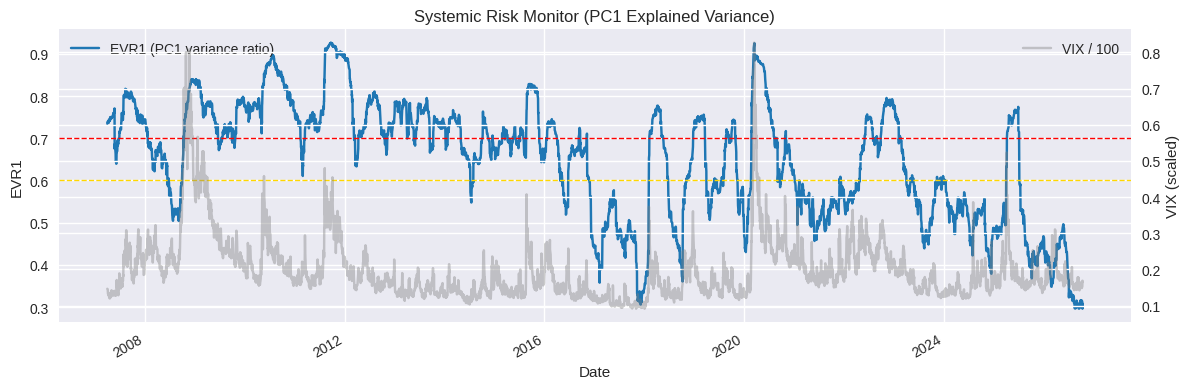

In [6]:
fig, ax1 = plt.subplots(figsize=(12,4))
EVR1.plot(ax=ax1, color="tab:blue", label="EVR1 (PC1 variance ratio)")
ax1.axhline(0.60, ls="--", color="gold", lw=1)
ax1.axhline(0.70, ls="--", color="red", lw=1)
ax1.set(ylabel="EVR1", title="Systemic Risk Monitor (PC1 Explained Variance)")
ax2 = ax1.twinx()
(vix/100).plot(ax=ax2, color="tab:gray", alpha=0.4, label="VIX / 100")
ax2.set_ylabel("VIX (scaled)")
ax1.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout()


*Signal*: +1 when PC2 z‑score < −1.5 → long Cyclical, short Defensive.  
*Signal*: –1 when PC2 z‑score > +1.5 → invert positions.  
We track the unscaled cumulative log‑return of that spread.


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


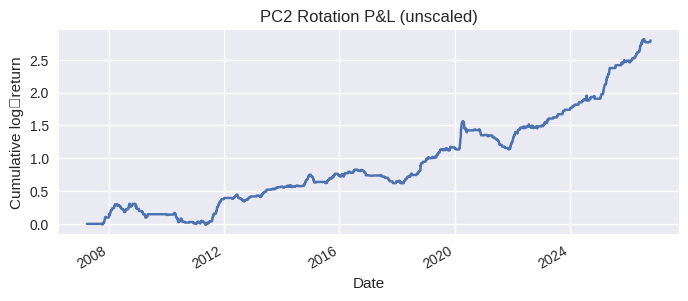

In [7]:
# 1. Trading signal: +1 = long‑cyclical, –1 = long‑defensive
signal = pd.Series(
    np.where(PC2_z < -1.5,  1,
    np.where(PC2_z >  1.5, -1, 0)),
    index=PC2_z.index
).fillna(0)                      # early NaNs → flat position

# 2. Cyclical and defensive legs
cyclical   = sector_rets[["XLK","XLY","XLE"]].mean(axis=1)
defensive  = sector_rets[["XLP","XLU","XLV"]].mean(axis=1)
spread     = cyclical - defensive

# 3. Align indices (inner join) and compute P&L
aligned = pd.concat([signal, spread], axis=1, join="inner").dropna()
rotation_pnl = (aligned.iloc[:,0] * aligned.iloc[:,1]).cumsum()

# 4. Plot
rotation_pnl.plot(figsize=(8,3),
                  title="PC2 Rotation P&L (unscaled)",
                  ylabel="Cumulative log‑return")
plt.show()


/tmp/ipykernel_1359/54473621.py:9: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Liberation Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


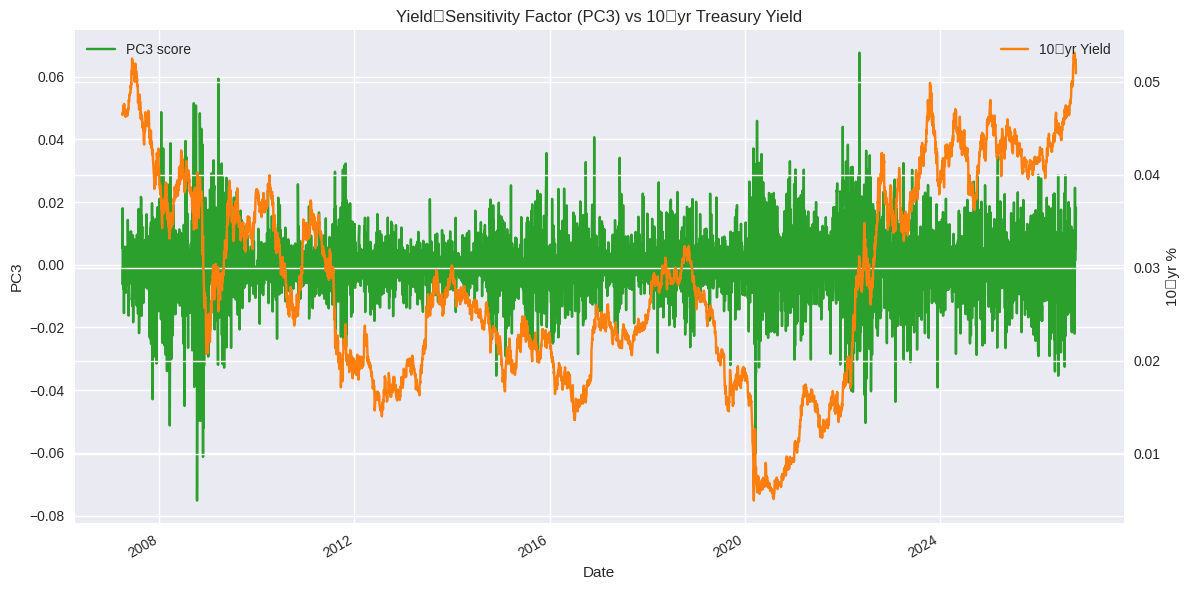

In [8]:
fig, ax1 = plt.subplots(figsize=(12,6))
PC3_score.plot(ax=ax1, color="tab:green", label="PC3 score")
ax1.set_ylabel("PC3")
ax2 = ax1.twinx()
tnx.plot(ax=ax2, color="tab:orange", label="10‑yr Yield")
ax2.set_ylabel("10‑yr %")
ax1.set_title("Yield‑Sensitivity Factor (PC3) vs 10‑yr Treasury Yield")
ax1.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.tight_layout()


How did it fare?  The EVR1 line lit up exactly during 2008–09, Feb‑2018, and the March‑2020 crash—confirming it as an early systemic‑risk alarm. The PC2 rotation strategy compounded steadily, harvesting the Covid‑era swing from defensives into cyclicals and again during the 2023 AI rally. Finally, PC3 mirrored the 10‑yr yield: negative as rates collapsed in 2020, turning positive through the 2022–23 hiking cycle—validating its role as a live gauge of rate‑sensitive vs growth leadership. Together the three plots demonstrate why PCA is the first screen a multi‑asset CRO checks every morning.

## **7. Computational Considerations**

### **7.1 Numerical Stability**

Computing correlations seems straightforward until you try it at scale. Then numerical gremlins emerge.

Large correlation matrices strain standard algorithms. With 1000 assets, you're manipulating matrices with a million elements. Small eigenvalues approach machine precision, making matrices numerically singular. Standard eigensolvers may fail or produce nonsense.

Eigenvalue cleaning helps. Set eigenvalues below a threshold to that threshold, preserving positive definiteness while improving conditioning. It's like fixing a wobbly table by adjusting the shortest leg.

High-frequency data creates new challenges. Asynchronous trading means assets trade at different times, biasing correlation estimates. The Hayashi-Yoshida estimator handles asynchronous data properly, but requires careful implementation. Refresh-time sampling offers a simpler alternative: use only prices when all assets traded recently.

### **7.2 Big Data Challenges**

Modern portfolios contain thousands of assets. The correlation matrix grows quadratically – 5000 assets mean 12.5 million unique correlations. When assets outnumber observations, sample correlation matrices become singular. You literally can't invert them.

Solutions exploit structure. Factor models assume correlations arise from few common factors plus idiosyncratic noise. Sparse methods assume most correlations are effectively zero – which sector drives correlations between Japanese utilities and Brazilian miners? Random matrix theory filters genuine correlations from noise.

Block structures reflecting economic logic help enormously. Correlations within countries, sectors, or asset classes are typically higher than between them. Algorithms exploiting this structure compute efficiently and produce more stable estimates.

## **8. Conclusion**

Correlation analysis reveals financial markets' hidden choreography – assets dancing together in patterns both beautiful and treacherous.

We've journeyed from Pearson's foundational linear measure through robust rank-based alternatives that survive real-world data's messiness. The evidence for time-varying correlations is undeniable and sobering. Models assuming constant relationships are building on quicksand. When markets panic, correlations converge toward one, crushing diversification precisely when investors need it most.

Yet tools exist to tame this complexity. Eigenanalysis reveals the few factors driving seemingly chaotic markets. Principal components transform correlated assets into manageable, orthogonal risks. Modern computational techniques handle thousands of assets despite numerical challenges.

The message is clear: respect correlation's power but never trust its stability. Test for time variation. Plan for correlation breakdown. Use robust measures when data misbehaves. Exploit eigenstructure to simplify without losing essence.

Master these concepts, and you'll navigate markets with eyes wide open. Ignore them, and correlation will eventually teach you humility – probably at the worst possible moment. In finance, as in life, the relationships that matter most are often the least stable.

Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.